# Módulo 1 — Análisis Descriptivo y Exploratorio para Decisiones de Modelado

**Fuentes primarias:**
1. **Superintendencia de Transporte** (`datos.gov.co`, dataset `eh75-8ah6`): *Operación de pasajeros y despacho de vehículos en la modalidad de transporte de pasajeros por carretera*.
2. **DANE — DIVIPOLA** (`datos.gov.co`, dataset `gdxc-w37w`): *Codificación de la División Político-Administrativa de Colombia* (nombres oficiales y coordenadas WGS84).
3. **Congreso de la República de Colombia — Ley 51 de 1983 (Ley Emiliani)**: calendario de festivos oficiales en Colombia.

**Objetivos de este notebook:**
1. Auditar la calidad de los datos (~49.2M registros): huecos temporales, fechas erróneas, despachos con cero pasajeros e inconsistencias DIVIPOLA.
2. Visualizar las **rutas reales en el mapa de Colombia** (red nacional de 52 terminales y corredores reales con paradas intermedias `ORIGEN -> TRANSITO -> DESTINO`).
3. Evaluar cuantitativamente la **factibilidad de seguir un mismo bus** sin ID de vehículo usando hora, terminal/parada, clase de vehículo y nivel de servicio.
4. Formular y contrastar **hipótesis explícitas sobre la demanda** (día de semana, festivos/puentes, Semana Santa, temporadas escolares, recuperación post-pandemia y asimetría ida/regreso).
5. Analizar **tendencia, estacionalidad (semanal y anual), autocorrelación (ACF/PACF) y sobredispersión** para aterrizar las **decisiones concretas de modelado** (ventana temporal, rutas, partición, rezagos, exógenas y función de pérdida).

## 1. Configuración y carga eficiente (Polars *lazy* + catálogo DIVIPOLA)

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

# Importar utilidades reutilizables desde src/
SRC_DIR = Path("../src").resolve()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from eda_utils import (
    FIGURES_DIR,
    PROCESSED_DIR,
    audit_calidad_datos,
    build_festivos_df,
    construir_serie_diaria,
    load_divipola,
    scan_operacion,
    top_rutas_con_divipola,
)
from rutas_mapa import (
    emparejar_buses_dia_ejemplo,
    estimar_rezago_viaje_corredor,
    evaluar_factibilidad_rastreo,
    mapa_corredor_real_paradas,
    mapa_red_nacional_colombia,
    mapear_terminales_divipola,
    obtener_paradas_corredor,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

lf = scan_operacion()
divipola = load_divipola()

print(f"Polars {pl.__version__} | DIVIPOLA cargado: {divipola.height:,} municipios oficiales (DANE)")

C:\Users\ADMON\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.stats import gaussian_kde


Polars 1.43.2 | DIVIPOLA cargado: 1,122 municipios oficiales (DANE)


## 2. Auditoría de calidad de datos y cobertura temporal

Antes de construir cualquier serie de tiempo debemos verificar si el periodo 2019–2026 es continuo o presenta huecos estructurales, errores de digitación o anomalías en el registro de pasajeros y códigos DIVIPOLA.

In [2]:
auditoria = audit_calidad_datos(lf)

print("=== 2.1 Fechas fuera de rango (anomalias de digitacion) ===")
display(auditoria["fechas_anomalas"])

print("\n=== 2.2 Resumen por tipo_despacho (ORIGEN vs TRANSITO) ===")
display(auditoria["resumen_tipo_despacho"])

print("\n=== 2.3 Resumen por clase_vehiculo (2021-2023, solo ORIGEN) ===")
display(auditoria["resumen_clase_vehiculo"])

=== 2.1 Fechas fuera de rango (anomalias de digitacion) ===


terminal,clase_vehiculo,nivel_servicio,municipio_origen_ruta,municipio_destino_ruta,fecha_despacho,hora_despacho,tipo_despacho,despachos,pasajeros
str,str,str,str,str,date,str,str,i32,i32
"""T.T. DE BUENAVENTURA""","""MICROBUS""","""LUJO""","""76109""","""76001""",2202-02-20,"""18""","""ORIGEN""",1,6
"""T.T. DE BUENAVENTURA""","""MICROBUS""","""LUJO""","""76109""","""76001""",2222-09-02,"""19""","""ORIGEN""",1,13
"""T.T. DE BUENAVENTURA""","""CAMIONETA""","""BASICO""","""76109""","""76001""",6202-04-13,"""19""","""ORIGEN""",1,7



=== 2.2 Resumen por tipo_despacho (ORIGEN vs TRANSITO) ===


tipo_despacho,registros,total_despachos,total_pasajeros,reg_cero_pasajeros,pct_cero_pasajeros,reg_despachos_gt1,pct_despachos_gt1,pax_por_despacho_medio,pax_por_despacho_p99,pax_por_despacho_max
str,u32,i32,i32,u32,f64,u32,f64,f64,f64,f64
"""ORIGEN""",39124095,40536101,334120767,4414638,11.28,1155396,2.95,8.27,36.0,70.0
"""TRANSITO""",10078714,10302996,86373986,2162146,21.45,186554,1.85,8.41,40.0,70.0



=== 2.3 Resumen por clase_vehiculo (2021-2023, solo ORIGEN) ===


clase_vehiculo,registros,total_despachos,total_pasajeros,pct_cero_pax,pax_desp_media,pax_desp_mediana,pax_desp_p95,pax_desp_p99,pax_desp_max
str,u32,i32,i32,f64,f64,f64,f64,f64,f64
"""BUS""",8321451,8533118,97640351,10.06,11.46,9.0,33.0,41.0,70.0
"""MICROBUS""",10536356,10940313,80785659,14.12,7.39,6.0,19.0,19.0,23.0
"""BUSETA""",3244730,3320228,21943567,19.88,6.62,5.0,19.0,25.0,36.0
"""CAMIONETA""",3355239,3471444,18388688,11.43,5.32,6.0,8.0,9.0,12.0
"""CAMPERO""",726696,782030,4842414,10.45,6.15,8.0,9.0,10.0,12.0
"""AUTOMOVIL""",1207556,1256422,3689290,10.6,2.94,4.0,4.0,5.0,5.0


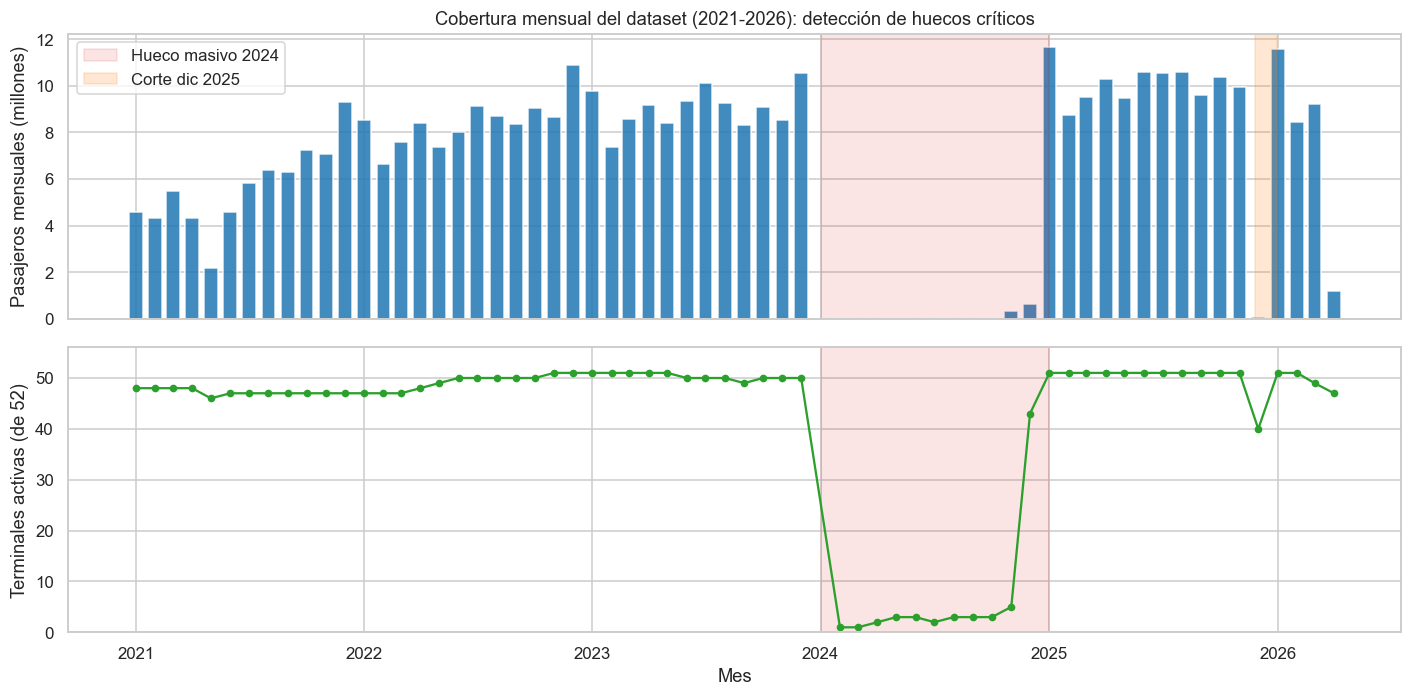

In [3]:
# Grafico de cobertura mensual 2021-2026: pasajeros y terminales activas
cob = auditoria["cobertura_mensual"].to_pandas()
cob["fecha_mes"] = pd.to_datetime(
    cob["anio"].astype(str) + "-" + cob["mes"].astype(str).str.zfill(2) + "-01"
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

ax1.bar(cob["fecha_mes"], cob["pasajeros"] / 1e6, width=22, color="#1f77b4", alpha=0.85)
ax1.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="#d62728", alpha=0.12, label="Hueco masivo 2024")
ax1.axvspan(pd.Timestamp("2025-11-25"), pd.Timestamp("2025-12-31"), color="#ff7f0e", alpha=0.18, label="Corte dic 2025")
ax1.set_ylabel("Pasajeros mensuales (millones)")
ax1.set_title("Cobertura mensual del dataset (2021-2026): detección de huecos críticos")
ax1.legend(loc="upper left")

ax2.plot(cob["fecha_mes"], cob["terminales_activas"], marker="o", ms=4, color="#2ca02c")
ax2.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="#d62728", alpha=0.12)
ax2.set_ylabel("Terminales activas (de 52)")
ax2.set_xlabel("Mes")
ax2.set_ylim(0, 56)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_01_cobertura_mensual.png", dpi=150, bbox_inches="tight")
plt.show()

### Hallazgos críticos de calidad (impacto directo en el modelado)
1. **Hueco estructural en 2024 y diciembre 2025:**
   - Entre **enero de 2021 y diciembre de 2023** (36 meses completos, 1.095 días), la cobertura es continua (47–51 terminales activas, ~8–11 millones de pasajeros/mes).
   - En **2024** hay una caída casi total del reporte (enero con 0 registros; febrero–octubre con apenas 1–3 terminales). En **diciembre de 2025** ocurre otro corte abrupto (solo ~88 mil pasajeros frente a ~10 millones mensuales).
   - **Decisión de modelado #1:** Utilizar la ventana continua **2021-01-01 a 2023-12-31 (3 años completos)** como serie principal para entrenamiento, validación y prueba. Esto evita contaminar ventanas de rezagos o estacionalidad anual con un año completo faltante en 2024, al tiempo que captura 3 ciclos anuales completos y la recuperación post-pandemia.
2. **Fechas anómalas:** Existen 3 registros con año `6202` (error de digitación en `T.T. DE BUENAVENTURA`), que deben filtrarse.
3. **Despachos con cero pasajeros:** Representan el **11.3%** en `ORIGEN` y el **21.5%** en `TRANSITO`. En `TRANSITO`, un registro con 0 pasajeros indica que el vehículo pasó por la terminal intermedia sin abordar nuevos pasajeros (no necesariamente que fuera vacío). En `ORIGEN`, ocurre con mayor frecuencia en rutas cortas de alta rotación o en registros de despacho sin venta registrada en taquilla.
4. **Agregación previa (`despachos > 1`):** Aunque la mayoría de filas corresponden a `despachos = 1`, alrededor del 2.9% en `ORIGEN` agrupan entre 2 y 20 despachos en una misma fila (razón por la cual `pasajeros` llega hasta 640 en una sola fila). Por eso la ocupación aparente debe medirse siempre como `pasajeros / despachos`.

## 3. Rutas reales en el mapa de Colombia y auditoría DIVIPOLA

Enriquecemos las rutas con el catálogo oficial **DIVIPOLA (DANE)** y proyectamos sobre la cartografía de Colombia:
1. La **red nacional** de las 52 terminales y las 30 rutas de mayor demanda (2021–2023, `tipo_despacho == "ORIGEN"`).
2. **Corredores reales con paradas intermedias** (`ORIGEN -> TRANSITO -> DESTINO`), donde se observa físicamente por qué ciudades y terminales pasa el bus.

In [4]:
terminales_df = mapear_terminales_divipola(lf, divipola, date(2021, 1, 1), date(2023, 12, 31))
top_rutas = top_rutas_con_divipola(lf, divipola, date(2021, 1, 1), date(2023, 12, 31), solo_origen=True, top_n=30)

print(f"Terminales mapeadas con coordenadas DIVIPOLA: {terminales_df.height} / 52 (sin coords: {terminales_df.filter(pl.col('latitud').is_null()).height})")
display(
    top_rutas.select([
        "ruta_id", "ruta_nombre", "origen_dpto", "destino_dpto",
        "pasajeros", "despachos", "pax_por_despacho",
        "dist_linea_recta_km", "cobertura_dias_pct", "pct_cero_pax"
    ]).head(20)
)

Terminales mapeadas con coordenadas DIVIPOLA: 51 / 52 (sin coords: 0)


ruta_id,ruta_nombre,origen_dpto,destino_dpto,pasajeros,despachos,pax_por_despacho,dist_linea_recta_km,cobertura_dias_pct,pct_cero_pax
str,str,str,str,i32,i32,f64,f64,f64,f64
"""05001_05615""","""MEDELLÍN -> RIONEGRO""","""ANTIOQUIA""","""ANTIOQUIA""",3227685,378300,8.53,25.2,100.0,1.18
"""50001_11001""","""VILLAVICENCIO -> BOGOTÁ, D.C.""","""META""","""BOGOTÁ, D.C.""",2601209,211972,12.27,79.1,99.6,12.17
"""76001_47570""","""SANTIAGO DE CALI -> PUEBLOVIEJ…","""VALLE DEL CAUCA""","""MAGDALENA""",2474405,338355,7.31,878.4,97.8,5.98
"""66001_63001""","""PEREIRA -> ARMENIA""","""RISARALDA""","""QUINDÍO""",2337691,193387,12.09,30.2,100.0,2.16
"""63001_63401""","""ARMENIA -> LA TEBAIDA""","""QUINDÍO""","""QUINDÍO""",2193388,252415,8.69,14.9,100.0,1.12
…,…,…,…,…,…,…,…,…,…
"""13001_08001""","""CARTAGENA DE INDIAS -> BARRANQ…","""BOLÍVAR""","""ATLÁNTICO""",1439925,109158,13.19,99.4,100.0,5.26
"""15759_11001""","""SOGAMOSO -> BOGOTÁ, D.C.""","""BOYACÁ""","""BOGOTÁ, D.C.""",1423131,123206,11.55,177.3,99.6,4.92
"""05045_05837""","""APARTADÓ -> TURBO""","""ANTIOQUIA""","""ANTIOQUIA""",1382297,420012,3.29,25.7,99.5,23.47


In [5]:
# Mapa interactivo de Colombia: 52 terminales + Top 30 rutas (resaltando anomalia DIVIPOLA 76001 -> 47570)
fig_red = mapa_red_nacional_colombia(top_rutas, terminales_df)
fig_red.write_html(FIGURES_DIR / "eda_02_mapa_red_nacional_colombia.html", include_plotlyjs="cdn")
fig_red.write_image(FIGURES_DIR / "eda_02_mapa_red_nacional_colombia.png", width=1100, height=780, scale=2)
fig_red.show()

### Inconsistencia detectada en los datos (DIVIPOLA): `76001 -> 47570`
Al proyectar las rutas en el mapa de Colombia salta a la vista una anomalía crítica (línea roja):
- La 3.ª ruta con más pasajeros del país aparece codificada como **`76001` (Santiago de Cali, Valle del Cauca) $\rightarrow$ `47570` (Puebloviejo, Magdalena)**, con **2.47 millones de pasajeros** en 2021–2023.
- Sin embargo, la distancia en línea recta es de **878 km**, el promedio es de apenas **7.3 pasajeros/despacho** y se opera en `BUSETA` y `MICROBUS` de servicio `BASICO` desde `T.T. DE CALI` sin paradas intermedias a lo largo del país.
- Esto evidencia un **error sistemático de codificación DIVIPOLA en el sistema de reporte de la terminal de Cali** (un destino metropolitano/regional cercano del Valle o Cauca mapeado erróneamente al código `47570`). Visualizar las rutas en el mapa real de Colombia permitió detectar esta anomalía antes de seleccionarla para modelado.

## 4. Corredores reales con paradas (`ORIGEN -> TRANSITO`) y factibilidad de seguir un mismo bus

Una pregunta clave de entendimiento operativo es: **¿es posible rastrear un mismo bus a lo largo de su recorrido si el dataset no trae placa ni ID del vehículo, usando únicamente la hora, la terminal (parada), la clase de vehículo y el nivel de servicio?**

Para responder con evidencia cuantitativa (y no con suposiciones), ejecutamos cuatro pruebas empíricas sobre los datos reales de 2023:
1. **Reconstrucción geográfica de corredores** (`ORIGEN` $\rightarrow$ terminales `TRANSITO` $\rightarrow$ `DESTINO`).
2. **Prueba de colisiones horarias:** ¿cuántos buses idénticos (misma ruta, terminal, clase y nivel) salen en la misma hora?
3. **Correlación cruzada temporal (`ORIGEN` en $t$ vs `TRANSITO` en $t + \Delta t$):** ¿se observa la "ola" de salidas pasando por las terminales intermedias con el tiempo real de viaje?
4. **Prueba de emparejamiento heurístico 1-a-1** en un día concreto.

In [6]:
# 4.1 Reconstruccion de dos corredores reales de larga distancia
paradas_cali_ipiales = obtener_paradas_corredor(lf, divipola, terminales_df, "76001", "52356", min_despachos=500)
print("=== Corredor 1: Cali (76001) -> Ipiales (52356) ===")
display(paradas_cali_ipiales[["terminal", "tipo_despacho", "nom_mpio", "dpto", "despachos", "pasajeros", "pct_cero_pax", "dist_desde_origen_km"]])

paradas_bog_cali = obtener_paradas_corredor(lf, divipola, terminales_df, "11001", "76001", min_despachos=1000)
print("\n=== Corredor 2: Bogota (11001) -> Cali (76001) (paradas con >= 1,000 despachos) ===")
display(paradas_bog_cali[["terminal", "tipo_despacho", "nom_mpio", "dpto", "despachos", "pasajeros", "pct_cero_pax", "dist_desde_origen_km"]])

=== Corredor 1: Cali (76001) -> Ipiales (52356) ===


,terminal,tipo_despacho,nom_mpio,dpto,despachos,pasajeros,pct_cero_pax,dist_desde_origen_km
0,T.T. DE CALI,ORIGEN,SANTIAGO DE CALI,VALLE DEL CAUCA,54707,1294889,0.4,0.0
1,T.T. DE POPAYÁN,TRANSITO,POPAYÁN,CAUCA,15089,294994,3.0,106.4
2,T.T. DE PASTO,TRANSITO,PASTO,NARIÑO,41901,31445,91.1,258.8



=== Corredor 2: Bogota (11001) -> Cali (76001) (paradas con >= 1,000 despachos) ===


,terminal,tipo_despacho,nom_mpio,dpto,despachos,pasajeros,pct_cero_pax,dist_desde_origen_km
0,T.T. DE BOGOTÁ SALITRE,ORIGEN,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",62054,1313381,1.0,0.0
1,T.T. DE BOGOTÁ SUR,TRANSITO,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",54993,418987,5.0,0.0
2,T.T. DE FUSAGASUGA,TRANSITO,FUSAGASUGÁ,CUNDINAMARCA,2022,7817,13.2,45.8
3,T.T. DE MELGAR,TRANSITO,MELGAR,TOLIMA,6805,32523,11.4,77.2
4,T.T. DE GIRARDOT,TRANSITO,GIRARDOT,CUNDINAMARCA,1004,13032,2.1,85.3
5,T.T. DE IBAGUÉ,TRANSITO,IBAGUÉ,TOLIMA,40652,346484,10.6,122.9
6,T.T. DE ARMENIA,TRANSITO,ARMENIA,QUINDÍO,26062,127864,32.0,174.9
7,T.T. DE TULÚA,TRANSITO,TULUÁ,VALLE DEL CAUCA,107420,1569171,4.6,240.1


In [7]:
# Mapas reales de ambos corredores sobre OpenStreetMap / Carto
fig_c1 = mapa_corredor_real_paradas(
    paradas_cali_ipiales, divipola, "76001", "52356",
    "Corredor real Cali -> Popayán -> Pasto -> Ipiales (ORIGEN y paradas TRANSITO)"
)
fig_c1.write_html(FIGURES_DIR / "eda_03_corredor_cali_ipiales.html", include_plotlyjs="cdn")
fig_c1.write_image(FIGURES_DIR / "eda_03_corredor_cali_ipiales.png", width=1000, height=680, scale=2)
fig_c1.show()

# Para Bogota -> Cali excluimos duplicado de terminal en origen para trazar una linea limpia
paradas_bog_cali_plot = paradas_bog_cali.drop_duplicates(subset=["cod_mpio"], keep="first")
fig_c2 = mapa_corredor_real_paradas(
    paradas_bog_cali_plot, divipola, "11001", "76001",
    "Corredor real Bogotá -> Girardot -> Ibagué -> Armenia -> Tuluá -> Buga -> Cali"
)
fig_c2.write_html(FIGURES_DIR / "eda_04_corredor_bogota_cali.html", include_plotlyjs="cdn")
fig_c2.write_image(FIGURES_DIR / "eda_04_corredor_bogota_cali.png", width=1000, height=680, scale=2)
fig_c2.show()

In [8]:
# 4.2 Auditoria cuantitativa de factibilidad de rastreo 1-a-1 (anio 2023)
fact = evaluar_factibilidad_rastreo(lf, date(2023, 1, 1), date(2023, 12, 31))

print("=== Prueba A: Colisiones en la misma hora (misma terminal, ruta, clase, nivel, fecha y hora) ===")
display(fact["colisiones"])

print("\n=== Prueba B: Cobertura de paradas intermedias (ORIGEN vs TRANSITO) en todas las rutas 2023 ===")
display(fact["resumen_origen_transito"])

=== Prueba A: Colisiones en la misma hora (misma terminal, ruta, clase, nivel, fecha y hora) ===


bloques_hora_totales,prop_bloque_1_bus,prop_bloque_multiples_buses,prop_bloque_5omas_buses,promedio_buses_por_bloque,max_buses_en_1_hora
u32,f64,f64,f64,f64,i32
4700894,0.594462,0.405538,0.092113,2.153406,298



=== Prueba B: Cobertura de paradas intermedias (ORIGEN vs TRANSITO) en todas las rutas 2023 ===


,categoria,n_rutas,pct_rutas
0,Solo ORIGEN (sin paradas intermedias registradas),1043,40.32
1,Ambas (ORIGEN y al menos 1 terminal TRANSITO),644,24.89
2,Solo TRANSITO (origen sin terminal o sin reporte),900,34.79


Pico Cali -> Popayan: lag = 3 h (r = 0.279)
Pico Cali -> Pasto:   lag = 10 h (r = 0.359)


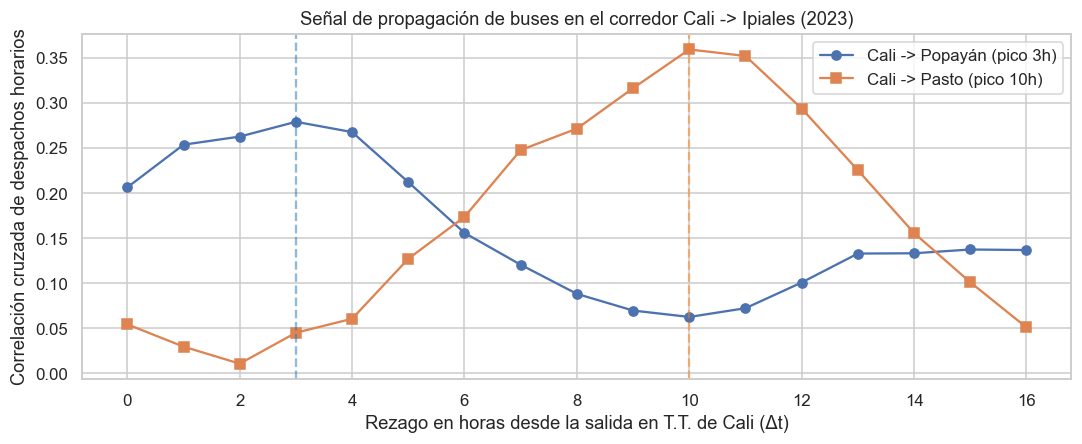

In [9]:
# 4.3 Prueba C: Correlacion cruzada temporal ORIGEN -> TRANSITO (tiempos reales de viaje)
lag_pop = estimar_rezago_viaje_corredor(lf, "76001", "52356", "T.T. DE CALI", "T.T. DE POPAYÁN", max_lag_horas=16)
lag_pas = estimar_rezago_viaje_corredor(lf, "76001", "52356", "T.T. DE CALI", "T.T. DE PASTO", max_lag_horas=16)

best_pop = lag_pop.loc[lag_pop["correlacion"].idxmax()]
best_pas = lag_pas.loc[lag_pas["correlacion"].idxmax()]
print(f"Pico Cali -> Popayan: lag = {int(best_pop['lag_horas'])} h (r = {best_pop['correlacion']:.3f})")
print(f"Pico Cali -> Pasto:   lag = {int(best_pas['lag_horas'])} h (r = {best_pas['correlacion']:.3f})")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(lag_pop["lag_horas"], lag_pop["correlacion"], marker="o", label=f"Cali -> Popayán (pico {int(best_pop['lag_horas'])}h)")
ax.plot(lag_pas["lag_horas"], lag_pas["correlacion"], marker="s", label=f"Cali -> Pasto (pico {int(best_pas['lag_horas'])}h)")
ax.axvline(best_pop["lag_horas"], color="#1f77b4", ls="--", alpha=0.5)
ax.axvline(best_pas["lag_horas"], color="#ff7f0e", ls="--", alpha=0.5)
ax.set_xlabel("Rezago en horas desde la salida en T.T. de Cali (Δt)")
ax.set_ylabel("Correlación cruzada de despachos horarios")
ax.set_title("Señal de propagación de buses en el corredor Cali -> Ipiales (2023)")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_05_correlacion_tiempos_viaje.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# 4.4 Prueba D: Emparejamiento heuristico 1-a-1 en un dia concreto (2023-06-15, Cali -> Popayan en ruta Cali->Ipiales)
emp = emparejar_buses_dia_ejemplo(
    lf, "76001", "52356", "T.T. DE CALI", "T.T. DE POPAYÁN",
    fecha=date(2023, 6, 15),
    lag_esperado_horas=int(best_pop["lag_horas"]),
    tolerancia_horas=1,
)
print(f"Buses despachados en ORIGEN (Cali, 2023-06-15): {emp['total_buses_origen']}")
print(f"Buses reportados en TRANSITO (Popayan, 48h):    {emp['total_buses_transito_48h']}")
print("Resultado del emparejamiento heuristico (±1h):", emp["resumen_estados"])
display(emp["detalle"].head(15))

Buses despachados en ORIGEN (Cali, 2023-06-15): 52
Buses reportados en TRANSITO (Popayan, 48h):    68
Resultado del emparejamiento heuristico (±1h): {'Ambiguo': 23, 'Sin emparejar': 20, 'Unico': 9}


,hora_origen,clase,nivel,pax_origen,hora_transito,pax_transito,candidatos_en_ventana,estado
0,2023-06-15 22:00:00,BUS,BASICO,28,2023-06-16 02:00:00,27.0,2,Ambiguo
1,2023-06-15 20:00:00,BUS,LUJO,56,NaT,NaN,0,Sin emparejar
2,2023-06-15 20:00:00,BUS,BASICO,33,2023-06-15 23:00:00,31.0,8,Ambiguo
3,2023-06-15 16:00:00,BUS,BASICO,17,2023-06-15 19:00:00,28.0,5,Ambiguo
4,2023-06-15 15:00:00,BUS,BASICO,19,2023-06-15 18:00:00,30.0,3,Ambiguo
5,2023-06-15 16:00:00,BUS,BASICO,18,2023-06-15 19:00:00,44.0,3,Ambiguo
6,2023-06-15 19:00:00,BUS,BASICO,17,2023-06-15 22:00:00,28.0,9,Ambiguo
7,2023-06-15 17:00:00,BUS,BASICO,14,2023-06-15 20:00:00,40.0,4,Ambiguo
8,2023-06-15 09:00:00,BUS,BASICO,9,2023-06-15 12:00:00,25.0,4,Ambiguo
9,2023-06-15 19:00:00,BUS,BASICO,38,2023-06-15 22:00:00,38.0,8,Ambiguo


### Veredicto sobre la factibilidad de seguir un mismo bus

| Dimensión | ¿Es factible? | Evidencia cuantitativa observada |
|---|---|---|
| **Reconstruir el corredor real (secuencia de paradas)** | **Sí** | En rutas largas (`Cali -> Ipiales`, `Bogotá -> Cali`), las terminales de `TRANSITO` trazan exactamente la carretera real (ej. Bogotá $\rightarrow$ Fusagasugá $\rightarrow$ Melgar $\rightarrow$ Girardot $\rightarrow$ Ibagué $\rightarrow$ Armenia $\rightarrow$ Tuluá $\rightarrow$ Buga $\rightarrow$ Cali). |
| **Estimar tiempos de viaje agregados entre terminales** | **Sí (a nivel de flujo)** | La correlación cruzada horaria recupera los tiempos reales de carretera: **Cali $\rightarrow$ Popayán = 3 h** ($r=0.28$), **Cali $\rightarrow$ Pasto = 10 h** ($r=0.36$). |
| **Rastrear determinísticamente un bus individual (1-a-1)** | **No** | 1) `hora_despacho` solo tiene resolución de **hora entera** (sin minutos); 2) **40.6%** de los bloques `(terminal, ruta, clase, nivel, fecha, hora)` tienen **más de 1 bus** saliendo en la misma hora (hasta 298 en rutas cortas); 3) no existe placa ni empresa operadora; 4) ~2.9% de filas ya vienen agregadas (`despachos > 1`); 5) en la prueba 1-a-1, muchos emparejamientos son **ambiguos** o **sin emparejar** (buses que no entran a la terminal intermedia o sufren retrasos de tráfico). |

**Decisión de modelado #2 (uso de `tipo_despacho`):**
- Para pronosticar la demanda diaria por ruta y dimensionar flota sin doble conteo de vehículos, la serie principal de cada ruta `(origen, destino)` debe construirse filtrando **`tipo_despacho == "ORIGEN"`**.
- Los registros `TRANSITO` son valiosos para entender paradas intermedias y tiempos de ciclo, pero mezclarlos con `ORIGEN` sumaría despachos del mismo vehículo en distintas terminales y distorsionaría el cálculo de flota requerida.

## 5. Selección de rutas representativas y contraste de hipótesis de demanda

Para construir un sistema representativo de una empresa intermunicipal (y cubrir tanto rutas de corta/media distancia como larga distancia y **pares bidireccionales ida/regreso**, necesarios para el cálculo de vueltas y flota), analizamos un portafolio de **6 series (3 pares bidireccionales + 1 corredor metropolitano de alta demanda)**:
- **Corta distancia / alta frecuencia:** `05001_05615` (Medellín $\rightarrow$ Rionegro)
- **Media distancia / turístico-regional (bidireccional):** `11001_50001` (Bogotá $\rightarrow$ Villavicencio) y `50001_11001` (Villavicencio $\rightarrow$ Bogotá)
- **Media-larga distancia (bidireccional):** `11001_73001` (Bogotá $\rightarrow$ Ibagué) y `73001_11001` (Ibagué $\rightarrow$ Bogotá)
- **Larga distancia nacional (bidireccional):** `11001_76001` (Bogotá $\rightarrow$ Cali) y `76001_11001` (Cali $\rightarrow$ Bogotá)

### Hipótesis explícitas a contrastar
- **H1 (Estacionalidad semanal):** La demanda aumenta significativamente entre viernes y domingo frente a martes–miércoles.
- **H2 (Festivos y puentes — Ley Emiliani):** Los días festivos y fines de semana con puente presentan incrementos marcados de demanda respecto a días ordinarios.
- **H3 (Temporadas altas anuales):** Existen picos recurrentes en **Semana Santa**, **vacaciones de mitad de año (junio–julio)** y **fin de año / Reyes (diciembre–enero)**.
- **H4 (Recuperación post-pandemia y choques):** 2021 presenta tendencia creciente (recuperación tras restricciones COVID-19) y una caída anómala en **mayo de 2021 (Paro Nacional en Colombia)**, estabilizándose en 2022–2023.
- **H5 (Asimetría ida vs. regreso):** En pares bidireccionales desde Bogotá, el sentido de salida (`Bogotá -> Destino`) tiene pico viernes–sábado, mientras el retorno (`Destino -> Bogotá`) tiene pico domingo–lunes festivo.

In [11]:
RUTAS_CANDIDATAS = {
    "05001_05615": ("05001", "05615", "Medellín -> Rionegro"),
    "11001_50001": ("11001", "50001", "Bogotá -> Villavicencio"),
    "50001_11001": ("50001", "11001", "Villavicencio -> Bogotá"),
    "11001_73001": ("11001", "73001", "Bogotá -> Ibagué"),
    "73001_11001": ("73001", "11001", "Ibagué -> Bogotá"),
    "11001_76001": ("11001", "76001", "Bogotá -> Cali"),
    "76001_11001": ("76001", "11001", "Cali -> Bogotá"),
}

series_dict = {}
resumen_series = []

for ruta_id, (ori, dst, nombre) in RUTAS_CANDIDATAS.items():
    df_s = construir_serie_diaria(lf, ori, dst, date(2021, 1, 1), date(2023, 12, 31), solo_origen=True)
    series_dict[ruta_id] = df_s
    y = df_s["pasajeros"]
    resumen_series.append({
        "ruta_id": ruta_id,
        "ruta": nombre,
        "dias_totales": len(df_s),
        "dias_sin_registro": int(df_s["dia_sin_registro"].sum()),
        "media_diaria": round(float(y.mean()), 1),
        "desv_std": round(float(y.std()), 1),
        "ratio_var_media": round(float(y.var() / max(y.mean(), 1)), 1),
        "mediana": round(float(y.median()), 1),
        "p90": round(float(y.quantile(0.90)), 1),
        "maximo": int(y.max()),
    })

resumen_df = pd.DataFrame(resumen_series)
display(resumen_df)

,ruta_id,ruta,dias_totales,dias_sin_registro,media_diaria,desv_std,ratio_var_media,mediana,p90,maximo
0,05001_05615,Medellín -> Rionegro,1095,0,2947.7,733.9,182.7,3136.0,3689.6,4882
1,11001_50001,Bogotá -> Villavicencio,1095,0,1028.1,505.2,248.3,992.0,1616.8,3724
2,50001_11001,Villavicencio -> Bogotá,1095,4,2375.5,1161.5,567.9,2176.0,3880.0,6992
3,11001_73001,Bogotá -> Ibagué,1095,0,837.7,460.3,253.0,727.0,1202.0,4950
4,73001_11001,Ibagué -> Bogotá,1095,0,1635.8,644.4,253.9,1556.0,2285.0,5396
5,11001_76001,Bogotá -> Cali,1095,27,1217.8,447.3,164.3,1233.0,1755.0,2766
6,76001_11001,Cali -> Bogotá,1095,31,1105.4,464.5,195.2,1104.0,1683.4,2989


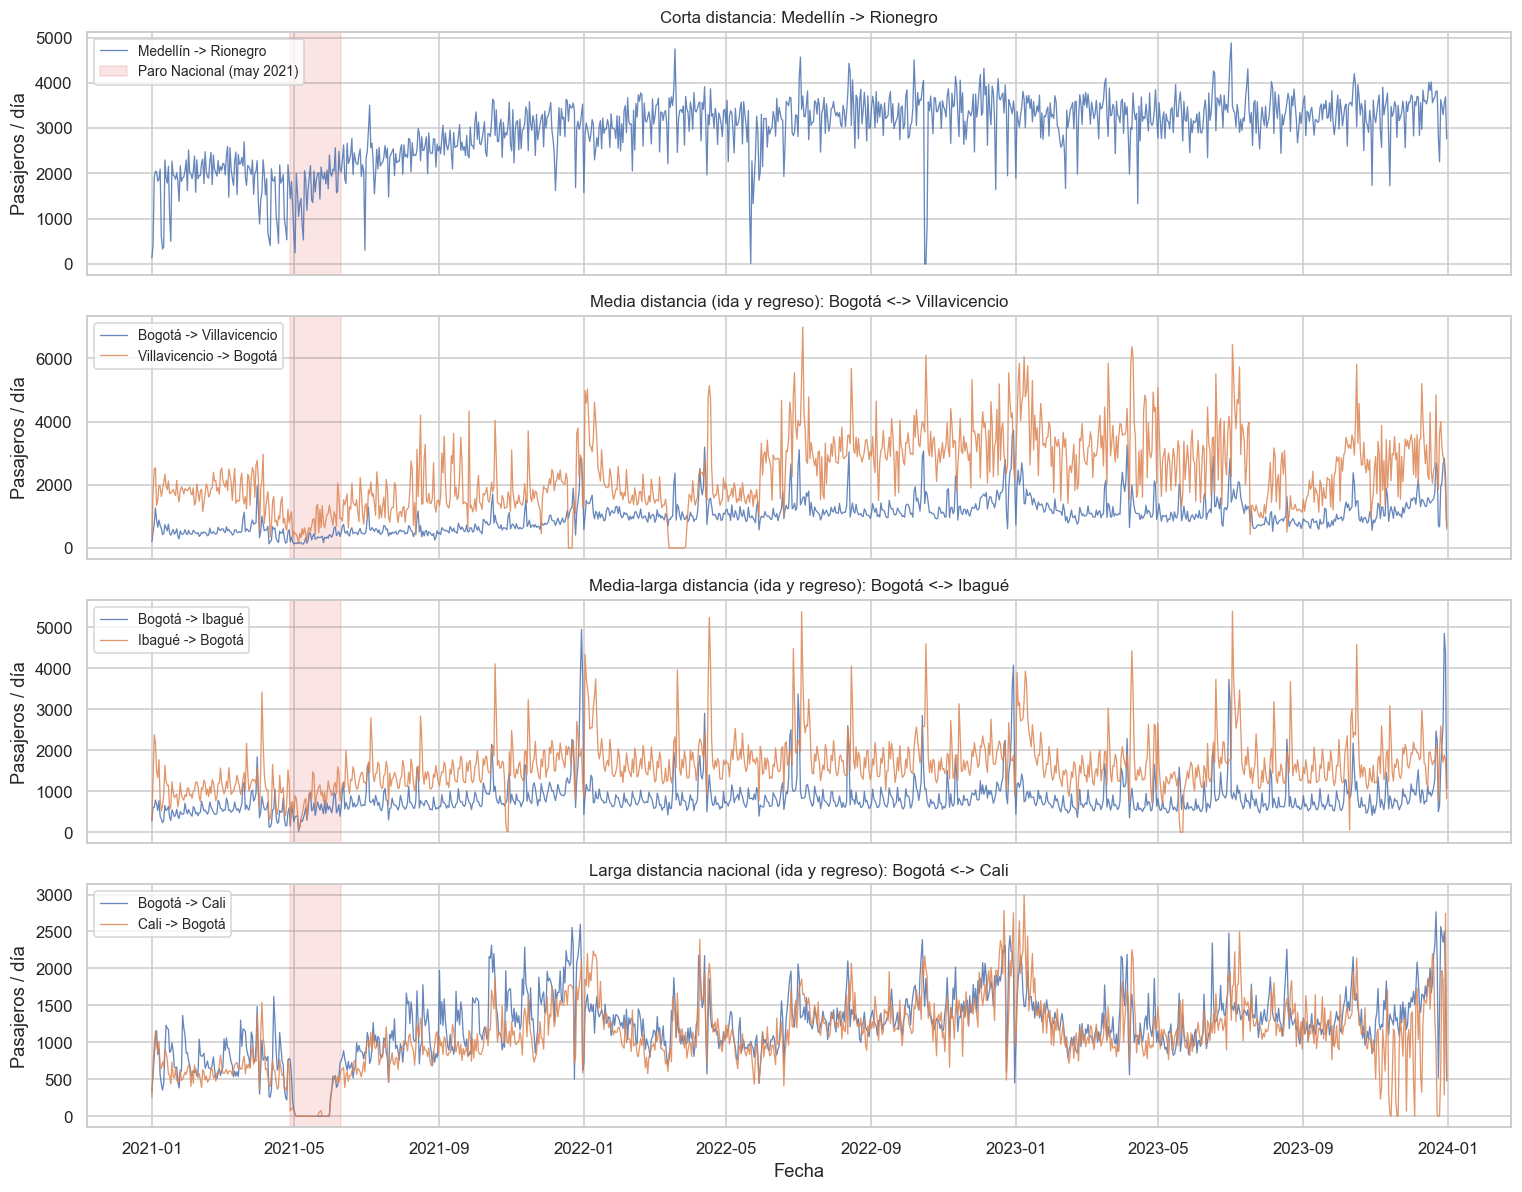

In [12]:
# Grafico de las series diarias de las rutas seleccionadas (2021-2023)
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
pares_plot = [
    (["05001_05615"], "Corta distancia: Medellín -> Rionegro"),
    (["11001_50001", "50001_11001"], "Media distancia (ida y regreso): Bogotá <-> Villavicencio"),
    (["11001_73001", "73001_11001"], "Media-larga distancia (ida y regreso): Bogotá <-> Ibagué"),
    (["11001_76001", "76001_11001"], "Larga distancia nacional (ida y regreso): Bogotá <-> Cali"),
]

for ax, (ids, titulo) in zip(axes, pares_plot):
    for rid in ids:
        df_s = series_dict[rid]
        ax.plot(df_s["fecha"], df_s["pasajeros"], lw=0.85, alpha=0.85, label=RUTAS_CANDIDATAS[rid][2])
    ax.axvspan(pd.Timestamp("2021-04-28"), pd.Timestamp("2021-06-10"), color="#d62728", alpha=0.12, label="Paro Nacional (may 2021)" if ax == axes[0] else None)
    ax.set_title(titulo, fontsize=11)
    ax.set_ylabel("Pasajeros / día")
    ax.legend(loc="upper left", fontsize=9)

axes[-1].set_xlabel("Fecha")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_06_series_rutas_candidatas.png", dpi=150, bbox_inches="tight")
plt.show()

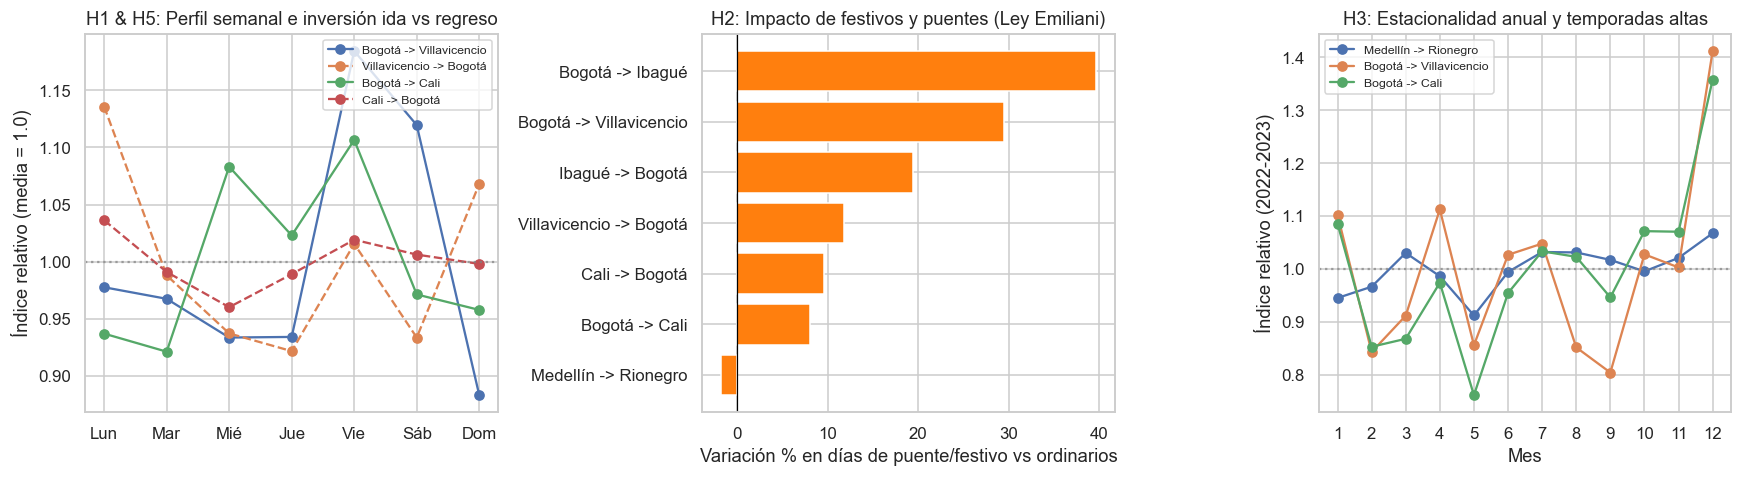

In [13]:
# Contraste de Hipotesis H1 (dia de semana), H2 (puentes/festivos), H3 (estacionalidad mensual) y H5 (asimetria ida/regreso)
dias_labels = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Perfil semanal ida vs regreso (Bogota <-> Villavicencio y Bogota <-> Cali)
for rid, ls in [("11001_50001", "-"), ("50001_11001", "--"), ("11001_76001", "-"), ("76001_11001", "--")]:
    df_s = series_dict[rid]
    perfil = df_s.groupby("dia_semana")["pasajeros"].mean()
    # Normalizar por la media de la ruta para comparar patrones relativos
    axes[0].plot(range(7), perfil / perfil.mean(), marker="o", ls=ls, label=RUTAS_CANDIDATAS[rid][2])
axes[0].axhline(1.0, color="gray", ls=":", alpha=0.7)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(dias_labels)
axes[0].set_ylabel("Índice relativo (media = 1.0)")
axes[0].set_title("H1 & H5: Perfil semanal e inversión ida vs regreso")
axes[0].legend(fontsize=8)

# Panel 2: Efecto de puentes festivos vs dias ordinarios (H2)
efecto_puente = []
for rid, (_, _, nombre) in RUTAS_CANDIDATAS.items():
    df_s = series_dict[rid]
    m_ord = df_s.loc[~df_s["es_puente"], "pasajeros"].mean()
    m_pte = df_s.loc[df_s["es_puente"], "pasajeros"].mean()
    efecto_puente.append({"ruta": nombre, "incremento_pct": (m_pte / m_ord - 1) * 100})
ep_df = pd.DataFrame(efecto_puente).sort_values("incremento_pct")
axes[1].barh(ep_df["ruta"], ep_df["incremento_pct"], color="#ff7f0e")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Variación % en días de puente/festivo vs ordinarios")
axes[1].set_title("H2: Impacto de festivos y puentes (Ley Emiliani)")

# Panel 3: Perfil mensual (H3: temporadas altas)
for rid in ["05001_05615", "11001_50001", "11001_76001"]:
    df_s = series_dict[rid]
    # Usar 2022-2023 para perfil estacional limpio (sin distorsion 2021)
    perfil_m = df_s[df_s["anio"] >= 2022].groupby("mes")["pasajeros"].mean()
    axes[2].plot(perfil_m.index, perfil_m / perfil_m.mean(), marker="o", label=RUTAS_CANDIDATAS[rid][2])
axes[2].axhline(1.0, color="gray", ls=":", alpha=0.7)
axes[2].set_xticks(range(1, 13))
axes[2].set_xlabel("Mes")
axes[2].set_ylabel("Índice relativo (2022-2023)")
axes[2].set_title("H3: Estacionalidad anual y temporadas altas")
axes[2].legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_07_hipotesis_demanda.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Descomposición en tendencia/estacionalidad y estructura de autocorrelación (ACF/PACF)

La descomposición **STL** (con periodo semanal = 7) y los correlogramas **ACF / PACF** permiten fundamentar directamente la longitud de la ventana de rezagos (*lookback window*) para el MLP y las arquitecturas secuenciales (LSTM/GRU/CNN-1D), así como los órdenes estacionales de SARIMA.

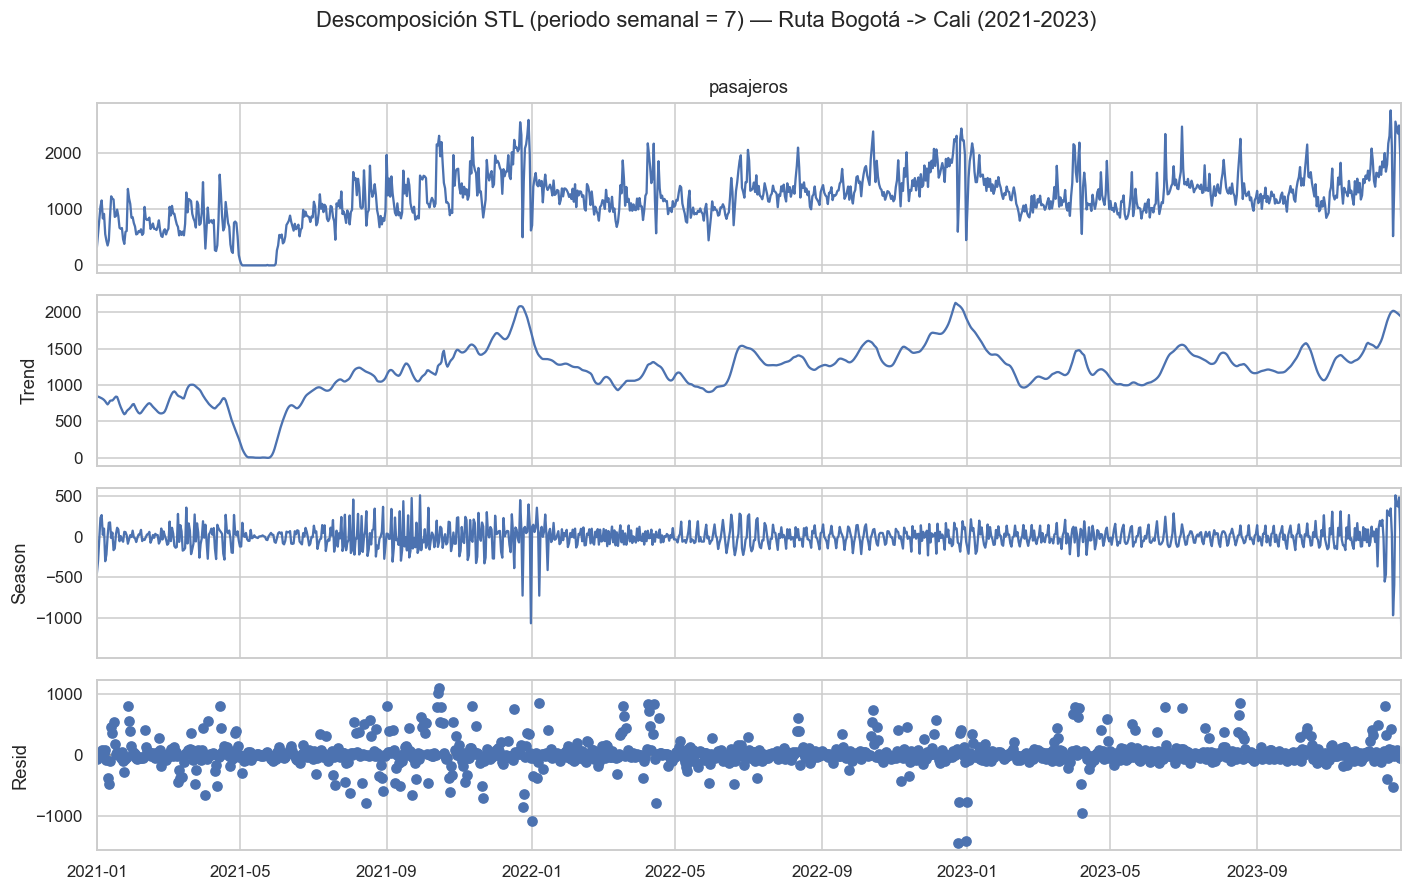

In [14]:
# Descomposicion STL sobre Bogota -> Cali (11001_76001) en 2021-2023
df_stl = series_dict["11001_76001"].set_index("fecha")["pasajeros"]
stl_res = STL(df_stl, period=7, robust=True).fit()

fig = stl_res.plot()
fig.set_size_inches(13, 8)
fig.suptitle("Descomposición STL (periodo semanal = 7) — Ruta Bogotá -> Cali (2021-2023)", y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_08_descomposicion_stl_bog_cali.png", dpi=150, bbox_inches="tight")
plt.show()

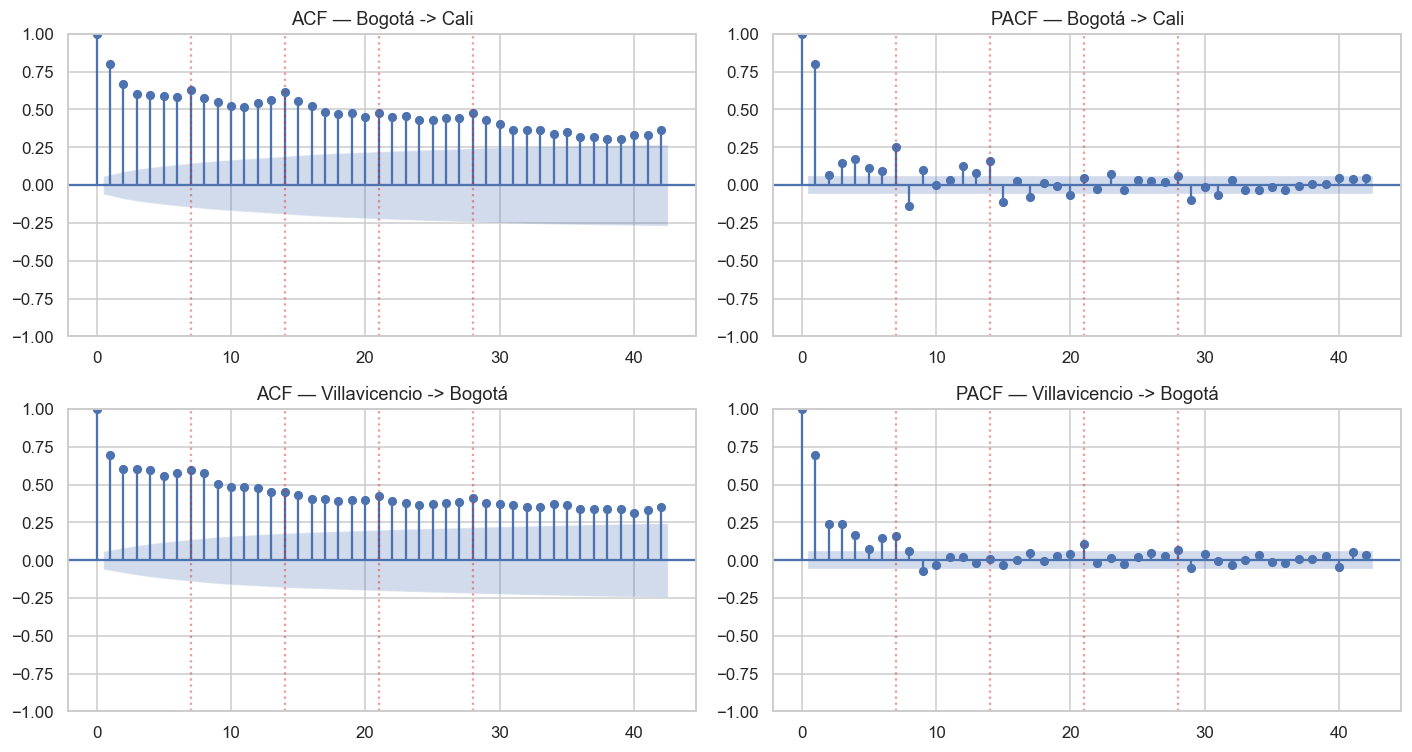

In [15]:
# ACF y PACF hasta 42 dias (6 semanas) para fundamentar longitud de ventana
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, rid in enumerate(["11001_76001", "50001_11001"]):
    s = series_dict[rid]["pasajeros"]
    plot_acf(s, lags=42, ax=axes[i, 0], title=f"ACF — {RUTAS_CANDIDATAS[rid][2]}")
    plot_pacf(s, lags=42, ax=axes[i, 1], method="ywm", title=f"PACF — {RUTAS_CANDIDATAS[rid][2]}")
    for ax in axes[i]:
        for lag in [7, 14, 21, 28]:
            ax.axvline(lag, color="#d62728", ls=":", alpha=0.45)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_09_acf_pacf.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Síntesis: Decisiones de modelado derivadas del EDA

Con base en la evidencia cuantitativa anterior, fijamos el diseño del pipeline de modelado para la siguiente fase:

| Aspecto | Decisión fundamentada por el EDA | Justificación cuantitativa |
|---|---|---|
| **Ventana temporal** | **`2021-01-01` a `2023-12-31`** (1.095 días continuos) | Evita el hueco estructural de 2024 (~99% faltante) y dic 2025; conserva 3 ciclos anuales completos. Se recomienda evaluar sensibilidad excluyendo/marcando el choque del Paro Nacional (mayo 2021). |
| **Definición de la serie** | Suma diaria de `pasajeros` por `(municipio_origen_ruta, municipio_destino_ruta)` filtrando **`tipo_despacho == "ORIGEN"`** | Evita doble conteo de buses en tránsito y excluye fechas erróneas (`>2026`). Los días sin registros (<2.5% en rutas seleccionadas) se imputan con `0` o se marcan explícitamente (`dia_sin_registro`) según si la terminal no reportó ese día. |
| **Exclusión de anomalías DIVIPOLA** | Excluir `76001 -> 47570` | Error de codificación detectado en mapa (878 km con busetas de 7.3 pax/despacho). |
| **Rastreo individual de buses** | **No modelar a nivel de bus individual** | Sin ID/placa, resolución horaria entera y 40.6% de colisiones por hora. En cambio, usar pares bidireccionales (`A->B` y `B->A`) para el modelo de vueltas/flota y tiempos de ciclo observados. |
| **Partición temporal sin fuga** | **Train:** 2021-01-01 a 2023-05-31 · **Val:** 2023-06-01 a 2023-08-31 · **Test (origen rodante 30d):** 2023-09-01 a 2023-12-31 | Garantiza orden estrictamente cronológico, cero fuga de información a 30 días y asegura **temporadas altas en prueba** (semana de receso oct, puentes nov, temporada decembrina). |
| **Ventana de rezagos (lookback)** | Probar ventanas de **28 y 56 días** (múltiplos de 7) | ACF/PACF muestran picos fuertes en rezagos 1, 7, 14, 21 y 28 días. |
| **Variables exógenas (conocidas $\ge 30$ días antes)** | Día de semana (sen/cos), mes/día del año (sen/cos), festivos oficiales (Ley 51/1983), puentes, víspera/retorno de puente, Semana Santa, temporada escolar/fin de año. | H1–H5 confirmadas empíricamente; todas las variables de calendario se conocen con >30 días de anticipación (cero fuga). |
| **Función de pérdida y cuantiles** | **Pérdida Poisson / Binomial Negativa (o Huber/L1 en log1p) + Pinball loss para P50, P75, P90, P95** | La variable objetivo es de **conteo no negativo con fuerte sobredispersión** ($\text{Var}/\mu \gg 1$, entre 50 y 1.000+), por lo que el error cuadrático puro subestima la asimetría y la cola superior relevante para dimensionar flota. |